# Example: A Synthetic Market of Many Stocks
In this example, we extend the jump hidden Markov model from one asset to a universe of stocks. Each synthetic stock's growth rate is the sum of a baseline, a market component, a sector component, and a stock-specific residual. The shared market and sector components make stocks move together.

We check that the synthetic stocks move together the way the real ones do. Then we save the fitted model, which we call the generator, so we can draw new synthetic markets later.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Separate the growth-rate components:__ Fit the single index model to each stock, and build each sector's factor from the residuals of the stocks in that sector.
> * __Build and simulate the sector factor model:__ Combine the saved market model with fitted models of the sector factors and the stock-specific residuals, and compose synthetic stocks from their baselines and the simulated components.
> * __Compare synthetic and real co-movement:__ Compare correlations within and across sectors, and each stock's volatility and market sensitivity, between a synthetic path and the real data, and between paths with and without the sector part.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
We load daily prices (2014 to 2024) with [the `MyTrainingMarketDataSet()` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyTrainingMarketDataSet) and each firm's sector in the [Global Industry Classification Standard (GICS)](https://www.msci.com/our-solutions/indexes/gics) with [the `MySP500SectorDataSet()` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MySP500SectorDataSet).

The universe is `SPY` plus every stock in the data with the full 2014 to 2024 price history and a GICS sector. We use every such stock, so that each sector factor averages many stocks. A firm with two classes of shares, such as News Corp, keeps one ticker.

The `tickers::Array{String,1}` array lists `SPY` first, then the stocks in sector order. The `prices::Array{Float64,2}` array holds closing prices (days × tickers). The `sectors::Array{String,1}` array holds sector labels for the stocks, excluding `SPY`:


In [2]:
tickers, prices, sectors = let

    # Load the data: daily prices (2014 to 2024) and GICS sectors -
    dataset = MyTrainingMarketDataSet()["dataset"]; # 2014 to 2024, one DataFrame per ticker
    sector_table = MySP500SectorDataSet(); # GICS sector of each firm
    sector_of = Dict{String,String}(); # ticker => GICS sector
    firm_of = Dict{String,Int}(); # ticker => CIK number, which identifies the firm
    for row ∈ eachrow(sector_table)
        sector_of[row.Symbol] = row."GICS Sector";
        firm_of[row.Symbol] = row.CIK;
    end

    # the rule: every stock with the full 2014 to 2024 history and a GICS sector, one ticker per firm -
    number_of_rows = nrow(dataset["SPY"]); # trading days in the full history
    candidates = String[]; # tickers that pass the rule
    firms_seen = Int[]; # CIK numbers of the firms already in the list
    for t ∈ sort(collect(keys(dataset))) # alphabetical order
        if t != "SPY" && nrow(dataset[t]) == number_of_rows && haskey(sector_of, t)
            if !(firm_of[t] ∈ firms_seen) # a firm with two share classes keeps its first ticker
                push!(candidates, t); # full history, a known sector, and a new firm
                push!(firms_seen, firm_of[t]);
            end
        end
    end

    # the sectors, each listed once, in alphabetical order -
    sector_names = String[];
    for t ∈ candidates
        if !(sector_of[t] ∈ sector_names)
            push!(sector_names, sector_of[t]); # a sector we have not seen yet
        end
    end
    sort!(sector_names);

    # sort the stocks by sector, so each sector forms one block -
    universe = String[];
    for s ∈ sector_names
        for t ∈ candidates
            if sector_of[t] == s
                push!(universe, t); # the stocks of sector s, in alphabetical order
            end
        end
    end

    # the tickers: SPY (the market) first, then the stocks -
    tickers = ["SPY"];
    append!(tickers, universe); # add the stocks to the end of the list, after SPY

    # closing prices: one row per trading day, one column per ticker (USD/share) -
    prices = zeros(number_of_rows, length(tickers));
    for j ∈ 1:length(tickers)
        prices[:, j] = dataset[tickers[j]].close; # column j holds the closing prices of tickers[j]
    end

    # the sector of each stock, SPY excluded -
    sectors = String[]; # start with an empty list of sector labels
    for t ∈ universe
        push!(sectors, sector_of[t]); # add the sector of stock t to the end of the list
    end
    println("$(length(universe)) stocks in $(length(sector_names)) sectors");

    # checks: full history for every ticker, and at least two stocks in every sector -
    for t ∈ tickers
        @assert nrow(dataset[t]) == number_of_rows "every ticker needs the full 2014-2024 history"
    end
    for s ∈ sector_names
        @assert count(sectors .== s) >= 2 "every sector needs at least two stocks" # sectors .== s is true for each stock in sector s
    end

    # return -
    (tickers, prices, sectors)
end;

375 stocks in 11 sectors


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values:

In [3]:
Δt = 1/252; # one trading day, expressed in years
number_of_states = 100; # number of hidden states in every jump hidden Markov model
ν = 5.0; # degrees of freedom of the Student-t distribution in each state
random_seed = 5660; # fix the random numbers, so every run gives the same paths
ϵ_range = range(1e-4, 5e-3, length = 6); # length = 6: six equally spaced candidate episode-start probabilities per day
λ_range = range(10.0, 160.0, length = 6); # length = 6: six equally spaced candidate mean episode lengths (trading days)
number_of_paths = 50; # simulated paths used to score each candidate (ϵ, λ) pair during tuning

# compute the daily growth rates of every ticker, in units of 1/yr (annualized)
G = JumpHMM.excess_growth_rates(prices;
    rf = 0.0, # annual risk-free growth rate to subtract (1/yr); zero keeps total growth
    Δt = Δt # time between closing prices, in years; used to annualize the growth rate
); # daily growth rates, days × tickers (1/yr)

# Get some dimensions of the data, for later use. 
number_of_days = size(G, 1); # number of growth rates (trading days)
number_of_stocks = length(tickers) - 1; # stocks in the universe, SPY excluded

___

## Task 1: Fit the Sector Factor Model
In this task, we reuse the tuned `SPY` model from the [single-asset example](../L13a/CHEME-5660-L13a-Example-JumpHMM-SPY-Fall-2026.ipynb) to fit the sector factor model. 

[The `JumpHMM.build(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.build-Tuple{Type{MyPortfolioModel},%20NamedTuple}) fits the model in three steps:
* __Market:__ It regresses each stock's growth rate $g_{i}(t)$ on the `SPY` growth rate $g_{m}(t)$ (the single index fit). This gives the baseline $\alpha_{i}$, the market sensitivity $\beta_{i}$, and the single index residual $\varepsilon_{i}(t)=g_{i}(t)-\alpha_{i}-\beta_{i}\,g_{m}(t)$, the part of the growth rate that the fit does not explain.
* __Sector:__ The sector factor $f_{s}(t)$ is the average single index residual of the $n_{s}$ stocks in sector $s$. The sector loading $\delta_{i}$ measures how strongly $\varepsilon_{i}(t)$ moves with the sector factor computed without stock $i$. Removing the sector part $\delta_{i}\,f_{s}(t)$ from $\varepsilon_{i}(t)$ leaves the stock-specific residual $u_{i}(t)$.
* __Jump hidden Markov models:__ The sector factor $f_{s}(t)$ and the stock-specific residual $u_{i}(t)$ are daily growth rates, like the growth rates of `SPY`. It fits a single-asset jump hidden Markov model to each of these growth rate series, as the single-asset example does for `SPY`.

We store the market model in `market_model::JumpHMM.MyJumpHiddenMarkovModel` and the fitted generator in `portfolio::JumpHMM.MyPortfolioModel`:


In [4]:
market_model, portfolio = let

    # load the tuned market model saved by the single-asset example -
    market_path = joinpath(_PATH_TO_DATA, "JumpHMM-SPY-2014-2024.jld2");
    market_model = load(market_path, "model");

    # fit the sector and stock residual models, retaining the saved market model -
    time_to_fit = @elapsed portfolio = JumpHMM.build(JumpHMM.MyPortfolioModel, (
        tickers = tickers, # one ticker per column of prices, SPY first
        prices = prices, # closing prices (USD/share), one row per trading day
        dependence = JumpHMM.MySectorFactorModel, # link stocks through shared market and sector components
        market = "SPY", # ticker whose price column supplies the market growth rates
        sector = sectors, # one sector label per non-market ticker, in the same order
        number_of_states = number_of_states, # growth-rate states in each newly fitted component model
        ν = ν, # Student-t degrees of freedom within each state; smaller values give heavier tails
        rf = 0.0, # annual risk-free growth rate to subtract (1/yr); zero keeps total growth
        Δt = Δt, # time between closing prices, in years
        sector_options = ( # additional fitting options passed to the sector factor model
            market_model = market_model, # reuse the tuned SPY model loaded above
        )
    ));
    # digits sets the number of decimal places in the displayed summaries (here: 1).
    println("fit in $(round(time_to_fit, digits = 1)) s");

    # checks: compatible growth rates, the saved market model, and all component models -
    # The saved model's Laplace location equals the median of the SPY growth rates it was fit to.
    # A model fit with a different rf or Δt has a different location and fails this check.
    @assert market_model.Δt == Δt && market_model.laplace_μ == median(G[:, 1]) "the saved market model must use the same growth-rate convention"
    @assert portfolio.dependence.market_model === market_model "reuse the saved SPY model"
    @assert length(portfolio.dependence.own_models) == number_of_stocks "one residual model per stock"
    @assert length(portfolio.dependence.sector_models) == length(unique(sectors)) "one model per sector"

    # return -
    (market_model, portfolio)
end;


fit in 1.4 s


Let's look at what the fit found in each sector. The table lists the number of stocks $n_{s}$ and the sector averages of the single index estimate $\hat{\beta}_{i}$ and of $R^{2}$. The $R^{2}$ of a stock is the fraction of the variance of its growth rate that the market explains.

The last two columns are the sector averages of the sector loading $\delta_{i}$ and of the residual scale $\psi_{i}$ that multiplies the stock-specific draw:

In [5]:
let

    # initialize: the fitted sector factor model, and the sectors in the order of the stocks -
    dep = portfolio.dependence;
    sector_names = unique(dep.sector);

    # one row per sector: the number of stocks and the sector averages -
    df = DataFrame(sector = String[], n = Int[], β = Float64[], R² = Float64[], δ = Float64[], ψ = Float64[]);
    for s ∈ sector_names
        members = findall(dep.sector .== s); # positions of the stocks in sector s
        push!(df, (s, length(members), mean(dep.β[members]), mean(dep.r²[members]), mean(dep.δ[members]), mean(dep.ψ[members])));
    end

    # let's display the sector averages in a table -
    pretty_table(df;
        column_labels = ["sector", "n_s", "average β̂", "average R²", "average δ", "average ψ"], # displayed column headings
        alignment = [:l, :r, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [3, 4, 5, 6])], # print the selected numeric columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

 ------------------------ ----- ----------- ------------ ----------- -----------
  sector                   n_s   average β̂   average R²   average δ   average ψ 
 ------------------------ ----- ----------- ------------ ----------- -----------
  Communication Services    14       0.896        0.291       0.687       1.021
  Consumer Discretionary    39       1.094        0.313       0.917       1.008
  Consumer Staples          31       0.604        0.202       0.934       1.007
  Energy                    16       1.199        0.267       0.975       1.025
  Financials                54       1.088        0.447       0.977       1.003
  Health Care               44       0.858        0.293       0.924       1.009
  Industrials               60       1.011        0.394       0.946       1.005
  Information Technology    50       1.240        0.429       0.931       1.005
  Materials                 17       1.041        0.331       0.875       1.024
  Real Estate               24      

> __What do we see?__ The average $R^{2}$ values are well below one: the market explains only part of each stock's daily moves.
>
> The average sector loadings $\delta_{i}$ are positive. A positive $\delta_{i}$ means that the single index residual $\varepsilon_{i}(t)$ of stock $i$, on average, moves with the residuals of the other stocks in its sector. After we remove the market, the stocks in each sector still move together.
>
> The average residual scales $\psi_{i}$ are close to one. In the data, each stock's sector part and stock-specific residual are nearly uncorrelated, as the simulation assumes. The stock-specific draw therefore needs little resizing.

___

## Task 2: Simulate the Synthetic Universe
In this task, we tune the jump behavior of the sector and stock residual models. Then we simulate one path of the whole universe. The saved `SPY` model stays fixed.

[The `JumpHMM.tune(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/tuning/) searches a grid of $(\epsilon,\lambda)$ values, as in the single-asset example, for the pair whose simulated paths best match the kurtosis and the volatility clustering of each model's data. Here $\epsilon$ is the daily probability that an episode starts, and $\lambda$ is the mean episode length in days.

[The `JumpHMM.sample_dependence(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/sector_factor/) then draws one path. Every stock shares the market draw, and every stock in a sector shares the sector draw. We save the tuned model in `tuned::JumpHMM.MyPortfolioModel`, the stock growth rates in `G_syn::Array{Float64,2}` (days × stocks), and the market growth rates in `g_m_syn::Array{Float64,1}`:


In [6]:
tuned, G_syn, g_m_syn = let

    # the generator saved at the end of Task 3: reuse it if it was tuned with the same settings, because tuning takes minutes -
    path = joinpath(_PATH_TO_DATA, "JumpHMM-SectorFactor-Universe-2014-2024.jld2");
    use_saved = false; # true when the saved generator matches the universe and the tuning settings
    if isfile(path) == true
        saved = load(path);
        if haskey(saved, "number_of_paths") == true # files saved before this check do not record the tuning settings
            same_universe = (saved["tickers"] == tickers && saved["N"] == number_of_states && saved["ν"] == ν && saved["Δt"] == Δt);
            same_tuning = (saved["ϵ_range"] == collect(ϵ_range) && saved["λ_range"] == collect(λ_range) &&
                saved["number_of_paths"] == number_of_paths && saved["seed"] == random_seed);
            use_saved = (same_universe && same_tuning);
        end
    end

    # load the saved generator, or tune the sector and stock residual models; the stock-only map leaves the saved SPY model fixed -
    if use_saved == true
        tuned = saved["portfolio"]; # the tuned generator from an earlier run
        println("loaded the tuned model from data/$(basename(path)); delete this file to tune again");
    else
        stock_columns = Dict{String,Int}(); # ticker => column of prices, stocks only
        for t ∈ portfolio.tickers
            stock_columns[t] = portfolio.tickers_map[t]; # column of stock t in prices
        end
        time_to_tune = @elapsed tuned = JumpHMM.tune(portfolio, prices;
            tickers_map = stock_columns, # stock columns in prices; omitting SPY keeps its saved market model fixed
            ϵ_range = ϵ_range, # candidate daily probabilities of starting a jump episode
            λ_range = λ_range, # candidate mean episode lengths, in trading days
            number_of_paths = number_of_paths, # simulated paths used to score each candidate (ϵ, λ) pair
            seed = random_seed # reproduce the random draws used during tuning
        );
        # digits sets the number of decimal places in the displayed summaries (here: 1).
        println("tuned in $(round(time_to_tune, digits = 1)) s");
    end

    # simulate one path of the whole universe -
    d = JumpHMM.sample_dependence(tuned.dependence, number_of_days;
        seed = random_seed # reproduce all market, sector, stock residual, and β draws
    );

    # checks: the saved market model, one column per stock, and finite growth rates -
    @assert tuned.dependence.market_model.transition == market_model.transition "tuning must preserve the saved SPY model"
    @assert size(d.G) == (number_of_days, number_of_stocks) "unexpected size of the synthetic path"
    @assert all(isfinite, d.G) "synthetic growth rates must be finite"

    # return -
    (tuned, d.G, d.g_m)
end;

loaded the tuned model from data/JumpHMM-SectorFactor-Universe-2014-2024.jld2; delete this file to tune again


Let's compare how the stocks move together. The table shows the average correlation of daily growth rates between pairs of stocks in the same sector and in different sectors. It compares the real data, the covariance matrix of the single index model, and the synthetic path.

The single index model gives two different stocks the covariance $\beta_{i}\beta_{j}\operatorname{Var}(g_{m})$, the market part only. We divide it by the standard deviations $\sigma_{i}$ and $\sigma_{j}$ of their real growth rates to get a correlation:

In [7]:
let

    # initialize: correlation matrices of the real and synthetic growth rates of the stocks -
    G_real = G[:, 2:end]; # drop SPY
    sector_index = tuned.dependence.sector_index; # sector number of each stock
    C_real = cor(G_real); # real correlation matrix
    C_syn = cor(G_syn); # synthetic correlation matrix

    # the correlation matrix of the single index model, from the real data -
    β = tuned.dependence.β; # single index market sensitivity of each stock
    var_m = var(G[:, 1]); # variance of the real market growth rate (1/yr^2)
    C_sim = zeros(number_of_stocks, number_of_stocks); # single index correlation matrix
    for i ∈ 1:number_of_stocks
        for j ∈ 1:number_of_stocks
            if i == j
                C_sim[i, j] = 1.0; # a stock is perfectly correlated with itself
            else
                C_sim[i, j] = β[i] * β[j] * var_m / (std(G_real[:, i]) * std(G_real[:, j])); # market part only
            end
        end
    end

    # sort the correlation of each pair of stocks by whether the two stocks share a sector -
    within_real = Float64[]; # real correlations, pairs in the same sector
    within_sim = Float64[]; # single index correlations, pairs in the same sector
    within_syn = Float64[]; # synthetic correlations, pairs in the same sector
    across_real = Float64[]; # real correlations, pairs in different sectors
    across_sim = Float64[]; # single index correlations, pairs in different sectors
    across_syn = Float64[]; # synthetic correlations, pairs in different sectors
    for i ∈ 1:number_of_stocks
        for j ∈ (i+1):number_of_stocks # j > i, so each pair is counted once
            if sector_index[i] == sector_index[j] # stocks i and j are in the same sector
                push!(within_real, C_real[i, j]); # add the real correlation of this pair to the list
                push!(within_sim, C_sim[i, j]); # add the single index correlation of this pair to the list
                push!(within_syn, C_syn[i, j]); # add the synthetic correlation of this pair to the list
            else # stocks i and j are in different sectors
                push!(across_real, C_real[i, j]);
                push!(across_sim, C_sim[i, j]);
                push!(across_syn, C_syn[i, j]);
            end
        end
    end

    # one row per kind of pair: the average correlation -
    df = DataFrame(pairs = ["same sector", "different sectors"],
        real = [mean(within_real), mean(across_real)],
        single_index = [mean(within_sim), mean(across_sim)],
        synthetic = [mean(within_syn), mean(across_syn)]);
    
    
    # let's display the correlation results in a table -
    pretty_table(df;
        column_labels = ["pairs of stocks", "real", "single index", "synthetic"], # displayed column headings, including units
        alignment = [:l, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [2, 3, 4])], # print the selected numeric columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

 ------------------- ------- -------------- -----------
  pairs of stocks      real   single index   synthetic 
 ------------------- ------- -------------- -----------
  same sector         0.474          0.355       0.486
  different sectors   0.345          0.325       0.342
 ------------------- ------- -------------- -----------


`Unhide` the code block below to see how we plotted the two correlation matrices, with the stocks in sector order, so each sector is a block on the diagonal.

> __What do we see?__ Both matrices show the sector blocks on the diagonal. Within a sector, the single index model gives a lower average correlation than the real data, because it sets the residual covariance of two stocks to zero. The sector factor adds this covariance, and the average synthetic correlation is close to the real one.
>
> Across sectors, the average single index and synthetic correlations are both close to the real one. The real matrix also shows pairs of sectors that move together more than the market explains, such as Real Estate and Utilities. The sector models are drawn independently, so only the shared market draw links different sectors.

Do the synthetic stocks move together like the real ones?

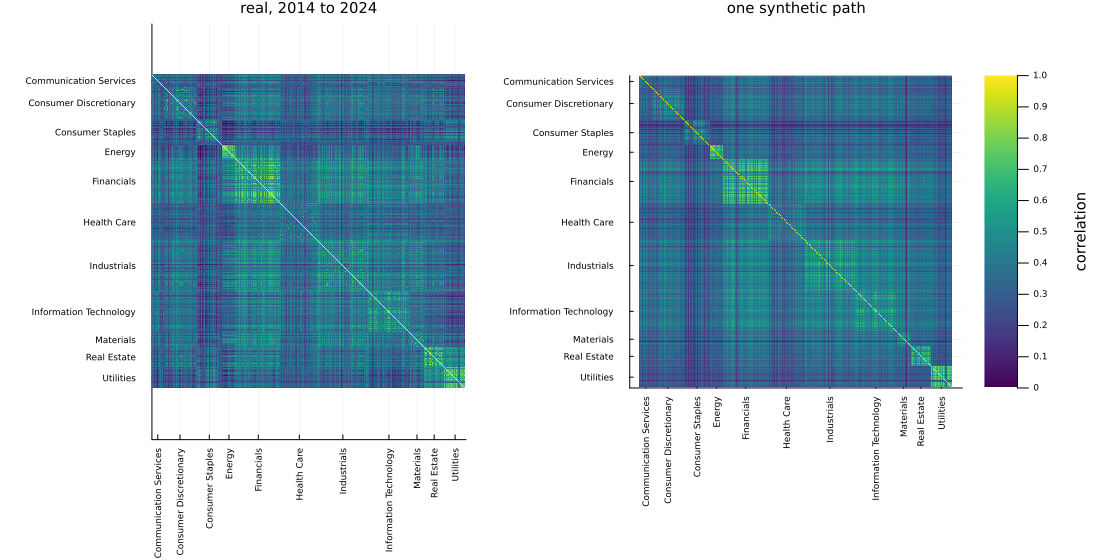

In [8]:
let

    # initialize: correlation matrices, stocks in sector order -
    dep = tuned.dependence;
    sector_names = unique(dep.sector); # the sectors, in the order of the stocks
    C_real = cor(G[:, 2:end]); # real correlation matrix
    C_syn = cor(G_syn); # synthetic correlation matrix

    # one tick at the middle of each sector block, labeled with the sector -
    tick_positions = Float64[];
    for s ∈ sector_names
        members = findall(dep.sector .== s); # positions of the stocks in sector s
        push!(tick_positions, (first(members) + last(members)) / 2); # middle of the block
    end

    # plot: real and synthetic, on one color scale -
    ticks = (tick_positions, sector_names); # label each sector block
    # display options used in this cell -
    # clims: Fix the heatmap color scale to the specified lower and upper values.
    # c: Choose the series color or, for a heatmap, the color palette.
    # yflip: Put the first matrix row at the top of the heatmap.
    # title: Set the title above each panel.
    # xticks: Set the x-axis tick positions and their labels.
    # yticks: Set the y-axis tick positions and their labels.
    # titlefontsize: Set the panel title font size in points.
    # xrotation: Rotate the x-axis tick labels by this angle in degrees.
    # tickfontsize: Set the tick-label font size in points.
    # colorbar: Show or hide the heatmap color scale.
    # colorbar_title: Label the quantity represented by the heatmap colors.
    # aspect_ratio: Draw each matrix entry as a square, so both panels have the same shape.
    # layout: Arrange the panels; widths gives the right panel extra room for its colorbar, so both heatmaps are the same size.
    # size: Set the complete figure width and height in pixels.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    p1 = heatmap(C_real, clims = (0, 1), c = :viridis, yflip = true, title = "real, 2014 to 2024", xticks = ticks, yticks = ticks,
        titlefontsize = 10, xrotation = 90, tickfontsize = 6, colorbar = false, aspect_ratio = :equal)
    p2 = heatmap(C_syn, clims = (0, 1), c = :viridis, yflip = true, title = "one synthetic path", xticks = ticks, yticks = ticks,
        titlefontsize = 10, xrotation = 90, tickfontsize = 6, colorbar_title = "correlation", aspect_ratio = :equal)
    plot(p1, p2, layout = grid(1, 2, widths = [0.415, 0.585]), size = (1100, 560), bottom_margin = 12Plots.mm, left_margin = 5Plots.mm)
end

Finally, let's compare each stock's volatility and β. For the synthetic path, we fit the single index model to the synthetic stock and the synthetic market draw. The table shows the averages over the stocks in each sector:

In [9]:
let

    # initialize: the real and synthetic market growth rates -
    g_m_real = G[:, 1]; # real market growth rates (1/yr)
    X_real = hcat(ones(number_of_days), g_m_real); # regressors for the real single index fit
    X_syn = hcat(ones(number_of_days), g_m_syn); # regressors for the synthetic single index fit

    # annualized volatility and single index β of each stock, real and synthetic -
    vol_real = zeros(number_of_stocks); # annualized volatility, real (1/sqrt(yr))
    vol_syn = zeros(number_of_stocks); # annualized volatility, synthetic (1/sqrt(yr))
    β_real = zeros(number_of_stocks); # single index β, real
    β_syn = zeros(number_of_stocks); # single index β, synthetic
    for i ∈ 1:number_of_stocks
        g_real = G[:, i + 1]; # real growth rates of stock i (column 1 of G is SPY)
        g_syn = G_syn[:, i]; # synthetic growth rates of stock i
        vol_real[i] = std(g_real) * sqrt(Δt); # annualized volatility of the real growth rates
        vol_syn[i] = std(g_syn) * sqrt(Δt); # annualized volatility of the synthetic growth rates
        coefficients_real = X_real \ g_real; # least squares fit of the single index model, [α, β]
        coefficients_syn = X_syn \ g_syn; # least squares fit to the synthetic stock, [α, β]
        β_real[i] = coefficients_real[2]; # keep β, the second coefficient
        β_syn[i] = coefficients_syn[2]; # keep β, the second coefficient
    end

    # one row per sector: the sector averages of the volatilities and β -
    dep = tuned.dependence;
    sector_names = unique(dep.sector); # the sectors, in the order of the stocks
    df = DataFrame(sector = String[], vol_real = Float64[], vol_syn = Float64[], β_real = Float64[], β_syn = Float64[]);
    for s ∈ sector_names
        members = findall(dep.sector .== s); # positions of the stocks in sector s
        push!(df, (s, mean(vol_real[members]), mean(vol_syn[members]), mean(β_real[members]), mean(β_syn[members])));
    end

    # let's display the volatility and β results in a table -
    pretty_table(df;
        column_labels = ["sector", "volatility, real", "volatility, synthetic", "β, real", "β, synthetic"], # displayed column headings, including units
        alignment = [:l, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [2, 3, 4, 5])], # print the selected numeric columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
    median_ratio = median(vol_syn ./ vol_real); # middle value of the synthetic-to-real volatility ratios
    # digits sets the number of decimal places in the displayed summaries (here: 3).
    println("median ratio of synthetic to real volatility: $(round(median_ratio, digits = 3))");
end

 ------------------------ ------------------ ----------------------- --------- --------------
  sector                   volatility, real   volatility, synthetic   β, real   β, synthetic 
 ------------------------ ------------------ ----------------------- --------- --------------
  Communication Services              0.291                   0.305     0.896          0.886
  Consumer Discretionary              0.342                   0.360     1.094          1.092
  Consumer Staples                    0.241                   0.259     0.604          0.600
  Energy                              0.407                   0.436     1.199          1.192
  Financials                          0.282                   0.298     1.088          1.092
  Health Care                         0.278                   0.299     0.858          0.862
  Industrials                         0.284                   0.300     1.011          1.011
  Information Technology              0.333                   0.357

> __What do we see?__ The average synthetic β estimates are close to the single index fits used by the generator.
>
> The synthetic volatilities are generally higher, with a median ratio of about 1.06. The fit chose $\psi_{i}$ so that the synthetic variance would match the real one. The fitted models reproduce that variance only approximately, and their jump episodes can add extra large moves.

___

## Task 3: Turn Off the Sector Part
In this task, we rebuild the synthetic path of Task 2 without the sector part, which gives the single index model. We keep the same market draw and the same stock-specific draws, so the sector part is the only change.

[The `JumpHMM.sample_draws(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.sample_draws) returns these draws for the seed of Task 2. Without the sector part, the stock-specific draw carries the whole variance of the single index residual. Setting $\delta_{i}=0$ in the formula for the residual scale gives $\psi_{i}^{2}=\operatorname{Var}(\varepsilon_{i})/\operatorname{Var}(u_{i})$.

We save the growth rates of the single index path in `G_sim::Array{Float64,2}` (days × stocks):


In [10]:
G_sim = let

    # initialize: the same random draws as the path in Task 2 -
    dep = tuned.dependence; # the tuned sector factor model
    draws = JumpHMM.sample_draws(dep, number_of_days;
        seed = random_seed # the seed of Task 2 gives the same market, sector, and stock-specific draws
    );

    # the variance of each stock's real single index residual (1/yr^2) -
    X_real = hcat(ones(number_of_days), G[:, 1]); # regressors for the real single index fit
    var_ε = zeros(number_of_stocks);
    for i ∈ 1:number_of_stocks
        coefficients = X_real \ G[:, i + 1]; # least squares fit of the single index model, [α, β]
        var_ε[i] = var(G[:, i + 1] .- X_real * coefficients); # variance of the single index residual
    end

    # compose each stock twice from the same draws: with the sector part (Task 2) and without it -
    G_sim = zeros(number_of_days, number_of_stocks); # single index path
    largest_difference = 0.0; # largest gap between the rebuilt sector factor path and the path of Task 2
    for i ∈ 1:number_of_stocks
        s = dep.sector_index[i]; # sector number of stock i
        ψ_sim = sqrt(var_ε[i] / dep.σ²_u[i]); # residual scale with δ_i = 0: the draw carries the whole residual variance
        for t ∈ 1:number_of_days
            g_sector = dep.α[i] + dep.β[i] * draws.g_m[t] + dep.δ[i] * draws.F[t, s] + dep.ψ[i] * draws.E[t, i]; # Task 2
            G_sim[t, i] = dep.α[i] + dep.β[i] * draws.g_m[t] + ψ_sim * draws.E[t, i]; # baseline + market + stock-specific
            largest_difference = max(largest_difference, abs(g_sector - G_syn[t, i]));
        end
    end

    # checks: the same draws as Task 2, and finite growth rates -
    # atol = 1e-8 sets the absolute tolerance (1/yr) for rebuilding the path of Task 2.
    @assert draws.g_m == g_m_syn "the single index path must reuse the market draw of Task 2"
    @assert largest_difference < 1e-8 "the same draws with the sector part must rebuild the path of Task 2"
    @assert all(isfinite, G_sim) "synthetic growth rates must be finite"

    # return -
    G_sim
end;

`Unhide` the code block below to see how we plotted the correlation matrices of the sector factor path and the single index path, with the stocks in sector order.

> __What do we see?__ The sector factor path shows one block for each sector on the diagonal. Without the sector part, the blocks disappear, and two stocks in the same sector move together about as much as two stocks in different sectors. Only the shared market draw links the stocks of the single index path.

What does the sector part add?

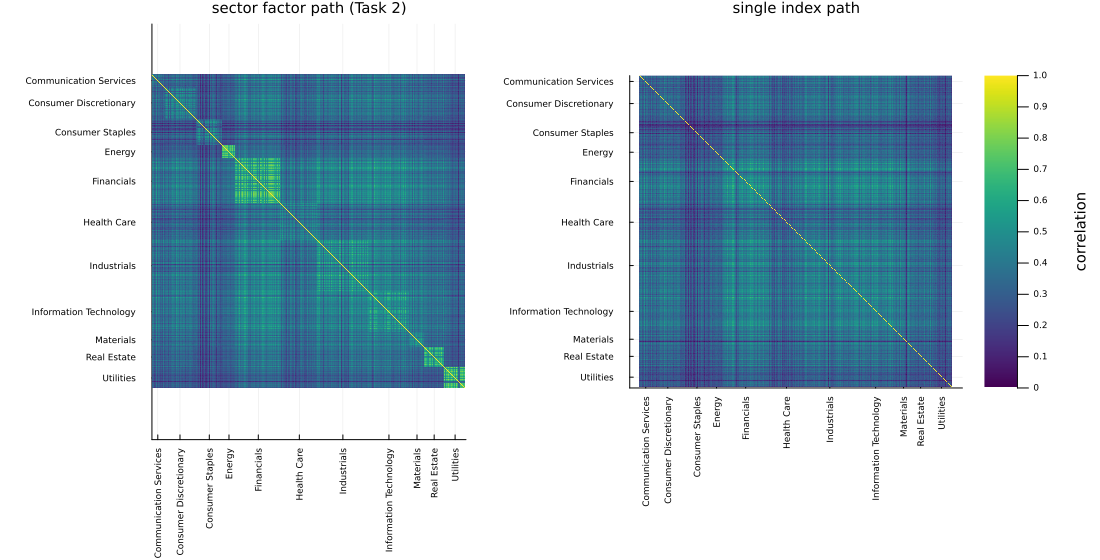

In [11]:
let

    # initialize: correlation matrices of the two synthetic paths, stocks in sector order -
    dep = tuned.dependence;
    sector_names = unique(dep.sector); # the sectors, in the order of the stocks
    C_syn = cor(G_syn); # sector factor path (Task 2)
    C_sim = cor(G_sim); # single index path

    # one tick at the middle of each sector block, labeled with the sector -
    tick_positions = Float64[];
    for s ∈ sector_names
        members = findall(dep.sector .== s); # positions of the stocks in sector s
        push!(tick_positions, (first(members) + last(members)) / 2); # middle of the block
    end

    # plot: the two synthetic paths, on one color scale -
    ticks = (tick_positions, sector_names); # label each sector block
    # display options used in this cell -
    # clims: Fix the heatmap color scale to the specified lower and upper values.
    # c: Choose the series color or, for a heatmap, the color palette.
    # yflip: Put the first matrix row at the top of the heatmap.
    # title: Set the title above each panel.
    # xticks: Set the x-axis tick positions and their labels.
    # yticks: Set the y-axis tick positions and their labels.
    # titlefontsize: Set the panel title font size in points.
    # xrotation: Rotate the x-axis tick labels by this angle in degrees.
    # tickfontsize: Set the tick-label font size in points.
    # colorbar: Show or hide the heatmap color scale.
    # colorbar_title: Label the quantity represented by the heatmap colors.
    # aspect_ratio: Draw each matrix entry as a square, so both panels have the same shape.
    # layout: Arrange the panels; widths gives the right panel extra room for its colorbar, so both heatmaps are the same size.
    # size: Set the complete figure width and height in pixels.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    p1 = heatmap(C_syn, clims = (0, 1), c = :viridis, yflip = true, title = "sector factor path (Task 2)", xticks = ticks, yticks = ticks,
        titlefontsize = 10, xrotation = 90, tickfontsize = 6, colorbar = false, aspect_ratio = :equal)
    p2 = heatmap(C_sim, clims = (0, 1), c = :viridis, yflip = true, title = "single index path", xticks = ticks, yticks = ticks,
        titlefontsize = 10, xrotation = 90, tickfontsize = 6, colorbar_title = "correlation", aspect_ratio = :equal)
    plot(p1, p2, layout = grid(1, 2, widths = [0.415, 0.585]), size = (1100, 560), bottom_margin = 12Plots.mm, left_margin = 5Plots.mm)
end

Finally, let's save the generator, so the synthetic markets can be drawn again without refitting. We write it to `data/JumpHMM-SectorFactor-Universe-2014-2024.jld2`, with the tickers, the sectors, and the first day's closing prices, which turn synthetic growth rates back into prices:

In [12]:
let

    # save the generator and what it needs to rebuild prices -
    path = joinpath(_PATH_TO_DATA, "JumpHMM-SectorFactor-Universe-2014-2024.jld2");
    save(path, Dict("portfolio" => tuned, "tickers" => tickers, "sectors" => sectors, "first_close" => prices[1, :],
        "N" => number_of_states, "ν" => ν, "Δt" => Δt,
        "ϵ_range" => collect(ϵ_range), "λ_range" => collect(λ_range), "number_of_paths" => number_of_paths, "seed" => random_seed);
        compress = true # compress the file: one fitted model per stock and sector makes it large
    );

    # checks: the file reloads, and the reloaded generator draws the same path -
    # seed = 1 fixes the same random draws for the original and reloaded generators.
    reloaded = load(path, "portfolio");
    G_original = JumpHMM.sample_dependence(tuned.dependence, 10; seed = 1).G; # 10 days from the generator in memory
    G_reloaded = JumpHMM.sample_dependence(reloaded.dependence, 10; seed = 1).G; # 10 days from the reloaded generator
    @assert G_reloaded == G_original "the saved generator should reproduce the same draws"
end

___

## Summary
In this example, we extended the jump hidden Markov model from one asset to a universe of stocks with the sector factor model, compared a synthetic path with the real data, and saved the generator.

> __Key Takeaways:__
>
> * __Baseline and factor contributions:__ We fitted each stock's baseline and market sensitivity with the single index model. We used the residuals to build sector factors and models of what remained after the sector contribution. This separated the shared sources of movement from the stock-specific residuals.
> * __Shared draws reproduce co-movement:__ We combined the saved market model with models of sector factors and stock-specific residuals. Shared market and sector draws made the stocks move together. On our synthetic path, the average correlations within and across sectors were close to the real ones.
> * __The sector part supplies the sector co-movement:__ We rebuilt the synthetic path from the same draws without the sector part, which gives the single index model. The average correlation of the stocks in the same sector fell in every sector. We saved the sector factor generator for later use.

Knowing how the synthetic universe is built also tells us its limits. For example, stocks in different sectors are linked only through the market draw.

___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___